In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.sparse import csr_matrix

# Notebook lives in CineXplain/notebooks, so data is one level up
DATA_DIR = os.path.join("..", "data")
print("Files in data folder:", os.listdir(DATA_DIR))

Files in data folder: ['links.csv', 'cache', 'ratings.csv', 'movies.csv']


In [2]:
ratings = pd.read_csv(os.path.join(DATA_DIR, "ratings.csv"))
movies = pd.read_csv(os.path.join(DATA_DIR, "movies.csv"))

print(ratings.shape, movies.shape)
display(ratings.head())
display(movies.head())
print(ratings.dtypes)

(32000204, 4) (87585, 3)


,userId,movieId,rating,timestamp
0,1,17,4.0,944249077
1,1,25,1.0,944250228
2,1,29,2.0,943230976
3,1,30,5.0,944249077
4,1,32,5.0,943228858


,movieId,title,genres
0,1,Toy Story (1995),Adventure|Animation|Children|Comedy|Fantasy
1,2,Jumanji (1995),Adventure|Children|Fantasy
2,3,Grumpier Old Men (1995),Comedy|Romance
3,4,Waiting to Exhale (1995),Comedy|Drama|Romance
4,5,Father of the Bride Part II (1995),Comedy


userId         int64
movieId        int64
rating       float64
timestamp      int64
dtype: object


In [3]:
print("Missing values:\n", ratings.isna().sum(), "\n")
print("Fully duplicated rows:", ratings.duplicated().sum())
print("Duplicate (user, movie) pairs:", ratings.duplicated(subset=["userId", "movieId"]).sum())
print("Rating range:", ratings.rating.min(), "to", ratings.rating.max())
print("Unique rating values:", sorted(ratings.rating.unique()))
print("Ratings whose movieId is missing from movies.csv:",
      (~ratings.movieId.isin(movies.movieId)).sum())

Missing values:
 userId       0
movieId      0
rating       0
timestamp    0
dtype: int64 

Fully duplicated rows: 0
Duplicate (user, movie) pairs: 0
Rating range: 0.5 to 5.0
Unique rating values: [np.float64(0.5), np.float64(1.0), np.float64(1.5), np.float64(2.0), np.float64(2.5), np.float64(3.0), np.float64(3.5), np.float64(4.0), np.float64(4.5), np.float64(5.0)]
Ratings whose movieId is missing from movies.csv: 0


In [4]:
n_users = ratings.userId.nunique()
n_movies = ratings.movieId.nunique()
n_ratings = len(ratings)

sparsity = 1 - n_ratings / (n_users * n_movies)
print(f"Users: {n_users}, Movies rated: {n_movies}, Ratings: {n_ratings}")
print(f"Possible cells: {n_users * n_movies:,}")
print(f"Density:  {100*(1-sparsity):.2f}%")
print(f"Sparsity: {100*sparsity:.2f}%")

Users: 200948, Movies rated: 84432, Ratings: 32000204
Possible cells: 16,966,441,536
Density:  0.19%
Sparsity: 99.81%


Ratings per user:
 count    200948.000000
mean        159.246193
std         282.025462
min          20.000000
25%          36.000000
50%          73.000000
75%         167.000000
max       33332.000000
dtype: float64 

Ratings per movie:
 count     84432.000000
mean        379.005638
std        2592.439791
min           1.000000
25%           2.000000
50%           5.000000
75%          25.000000
max      102929.000000
dtype: float64 

Movies with only 1 rating: 18607


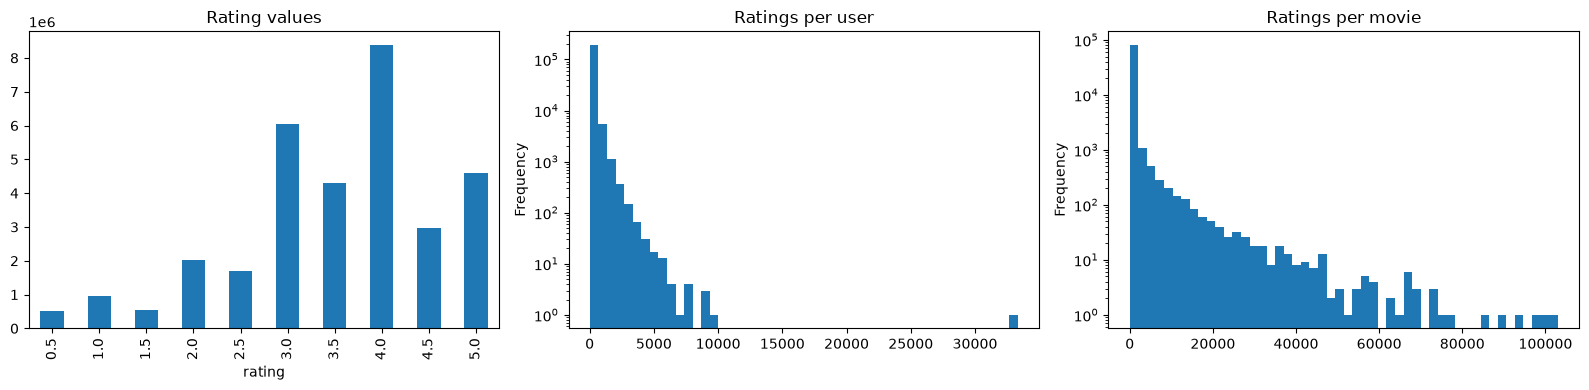

In [5]:
user_counts = ratings.groupby("userId").size()
movie_counts = ratings.groupby("movieId").size()

print("Ratings per user:\n", user_counts.describe(), "\n")
print("Ratings per movie:\n", movie_counts.describe(), "\n")
print("Movies with only 1 rating:", (movie_counts == 1).sum())

fig, ax = plt.subplots(1, 3, figsize=(16, 4))
ratings.rating.value_counts().sort_index().plot(kind="bar", ax=ax[0], title="Rating values")
user_counts.plot(kind="hist", bins=50, ax=ax[1], title="Ratings per user"); ax[1].set_yscale("log")
movie_counts.plot(kind="hist", bins=50, ax=ax[2], title="Ratings per movie"); ax[2].set_yscale("log")
plt.tight_layout(); plt.show()

In [6]:
# Map raw IDs to compact 0..n-1 indices
user_ids = np.sort(ratings.userId.unique())
movie_ids = np.sort(ratings.movieId.unique())
user_to_idx = {u: i for i, u in enumerate(user_ids)}
movie_to_idx = {m: i for i, m in enumerate(movie_ids)}

rows = ratings.userId.map(user_to_idx).values
cols = ratings.movieId.map(movie_to_idx).values
user_item = csr_matrix((ratings.rating.values, (rows, cols)),
                       shape=(len(user_ids), len(movie_ids)))

print("Matrix shape:", user_item.shape)
print("Stored entries:", user_item.nnz)
print("Memory (sparse, MB):", round((user_item.data.nbytes + user_item.indices.nbytes + user_item.indptr.nbytes)/1e6, 2))
print("Memory if dense (MB):", round(user_item.shape[0]*user_item.shape[1]*8/1e6, 1))

# Spot check against the raw data
u, m = ratings.userId.iloc[0], ratings.movieId.iloc[0]
print("Raw rating:", ratings.rating.iloc[0], "| matrix value:", user_item[user_to_idx[u], movie_to_idx[m]])

Matrix shape: (200948, 84432)
Stored entries: 32000204
Memory (sparse, MB): 384.81
Memory if dense (MB): 135731.5
Raw rating: 4.0 | matrix value: 4.0


In [7]:
def per_user_split(df, test_ratio=0.2, seed=42):
    """Hold out test_ratio of each user's ratings. Every user keeps training data."""
    rng = np.random.RandomState(seed)
    test_idx = []
    for _, grp in df.groupby("userId"):
        n_test = max(1, int(round(len(grp) * test_ratio)))
        test_idx.extend(rng.choice(grp.index, size=n_test, replace=False))
    test = df.loc[test_idx]
    train = df.drop(test.index)
    return train.reset_index(drop=True), test.reset_index(drop=True)

train, test = per_user_split(ratings)
print("Train:", len(train), "| Test:", len(test), "| Test share:", round(len(test)/len(ratings), 3))
print("Overlap (must be 0):", len(set(zip(train.userId, train.movieId)) & set(zip(test.userId, test.movieId))))
print("Users in test but not train (must be 0):", len(set(test.userId) - set(train.userId)))
print("Movies in test but not train:", len(set(test.movieId) - set(train.movieId)))

Train: 25601239 | Test: 6398965 | Test share: 0.2
Overlap (must be 0): 0
Users in test but not train (must be 0): 0
Movies in test but not train: 4177


In [8]:
import os

# ---- settings (change here only) ----
MIN_MOVIE_RATINGS = 50
N_DEV_USERS = 30000
TEST_RATIO = 0.2
SEED = 42
RELEVANT_THRESHOLD = 4.0

# 1) keep popular movies
mc = ratings.groupby("movieId").size()
keep_movies = mc.index[mc >= MIN_MOVIE_RATINGS]
df = ratings[ratings.movieId.isin(keep_movies)]

# 2) sample users who still have >= 20 ratings after filtering
uc = df.groupby("userId").size()
eligible = uc.index[uc >= 20]
rng = np.random.RandomState(SEED)
dev_users = rng.choice(eligible, size=N_DEV_USERS, replace=False)
df = df[df.userId.isin(dev_users)].copy()
print("Working set -> movies:", df.movieId.nunique(), "| users:", df.userId.nunique(), "| ratings:", len(df))

# 3) per-user 80/20 random split
df["_r"] = rng.random_sample(len(df))
df["_rank"] = df.groupby("userId")["_r"].rank(method="first") - 1
n_user = df.groupby("userId")["rating"].transform("size")
n_test = np.maximum(1, np.round(n_user * TEST_RATIO)).astype(int)
is_test = df["_rank"] < n_test
train = df[~is_test].drop(columns=["_r", "_rank"]).reset_index(drop=True)
test = df[is_test].drop(columns=["_r", "_rank"]).reset_index(drop=True)

# 4) sanity checks
print("Train:", len(train), "| Test:", len(test), "| Test share:", round(len(test) / len(df), 3))
print("Overlap (must be 0):", len(pd.merge(train[["userId", "movieId"]], test[["userId", "movieId"]])))
print("Users in test not train (must be 0):", len(set(test.userId) - set(train.userId)))
print("Movies in test not train:", len(set(test.movieId) - set(train.movieId)))
print("Share of test ratings >= relevance threshold:", round((test.rating >= RELEVANT_THRESHOLD).mean(), 3))
print("Min train ratings for any user:", train.groupby("userId").size().min())

# 5) save so we don't recompute (data/cache should be git-ignored)
os.makedirs(os.path.join(DATA_DIR, "cache"), exist_ok=True)
train.to_pickle(os.path.join(DATA_DIR, "cache", "cf_train.pkl"))
test.to_pickle(os.path.join(DATA_DIR, "cache", "cf_test.pkl"))

Working set -> movies: 16034 | users: 30000 | ratings: 4679787
Train: 3743885 | Test: 935902 | Test share: 0.2
Overlap (must be 0): 0
Users in test not train (must be 0): 0
Movies in test not train: 1
Share of test ratings >= relevance threshold: 0.502
Min train ratings for any user: 16


In [9]:
# Index maps built from TRAIN only (no leakage)
user_ids = np.sort(train.userId.unique())
movie_ids = np.sort(train.movieId.unique())
user_to_idx = {u: i for i, u in enumerate(user_ids)}
movie_to_idx = {m: i for i, m in enumerate(movie_ids)}

R = csr_matrix((train.rating.values.astype(np.float32),
                (train.userId.map(user_to_idx).values, train.movieId.map(movie_to_idx).values)),
               shape=(len(user_ids), len(movie_ids)))
user_mean = np.asarray(R.sum(1)).ravel() / np.diff(R.indptr)

print("Train matrix (users x movies):", R.shape, "| ratings stored:", R.nnz)
print("Average of user means:", round(user_mean.mean(), 3))

Train matrix (users x movies): (30000, 16033) | ratings stored: 3743885
Average of user means: 3.711


In [10]:
import time
t = time.time()

# Subtract each user's mean rating (so a "4" from a harsh rater counts more than a "4" from a generous one),
# then compare movies by cosine similarity of their user columns.
Rc = R.copy()
Rc.data = Rc.data - np.repeat(user_mean, np.diff(Rc.indptr)).astype(np.float32)
X = Rc.T.tocsr()                                   # movies x users
norms = np.sqrt(np.asarray(X.multiply(X).sum(1)).ravel()); norms[norms == 0] = 1
X = csr_matrix(X.multiply(1 / norms[:, None]), dtype=np.float32)

K = 50
nI = X.shape[0]
nbr_idx = np.zeros((nI, K), dtype=np.int32)
nbr_sim = np.zeros((nI, K), dtype=np.float32)
XT = X.T.tocsc()
for s in range(0, nI, 1000):                       # block by block so memory stays small
    blk = (X[s:s + 1000] @ XT).toarray()
    for j in range(blk.shape[0]):
        blk[j, s + j] = -1                          # a movie is not its own neighbour
    top = np.argpartition(-blk, K, axis=1)[:, :K]
    ts = np.take_along_axis(blk, top, 1)
    order = np.argsort(-ts, 1)
    nbr_idx[s:s + 1000] = np.take_along_axis(top, order, 1)
    nbr_sim[s:s + 1000] = np.take_along_axis(ts, order, 1)

print("Similarity time:", round(time.time() - t, 1), "s")

movie_title = movies.set_index("movieId").title
def show_neighbours(title, n=8):
    mid = movies.movieId[movies.title == title].iloc[0]
    i = movie_to_idx[mid]
    print("\n", title)
    for j in range(n):
        print("  ", round(float(nbr_sim[i, j]), 3), movie_title[movie_ids[nbr_idx[i, j]]])

show_neighbours("Toy Story (1995)")
show_neighbours("Matrix, The (1999)")

Similarity time: 13.1 s

 Toy Story (1995)
   0.302 Toy Story 2 (1999)
   0.193 Monsters, Inc. (2001)
   0.192 Toy Story 3 (2010)
   0.176 Back to the Future (1985)
   0.171 Finding Nemo (2003)
   0.169 Lion King, The (1994)
   0.154 Incredibles, The (2004)
   0.147 Raiders of the Lost Ark (Indiana Jones and the Raiders of the Lost Ark) (1981)

 Matrix, The (1999)
   0.283 Fight Club (1999)
   0.23 Star Wars: Episode V - The Empire Strikes Back (1980)
   0.219 Lord of the Rings: The Fellowship of the Ring, The (2001)
   0.215 Memento (2000)
   0.207 Terminator 2: Judgment Day (1991)
   0.206 Shawshank Redemption, The (1994)
   0.205 Lord of the Rings: The Two Towers, The (2002)
   0.2 Lord of the Rings: The Return of the King, The (2003)


In [11]:
# Neighbour weights as a sparse matrix (only positive similarities count)
w = np.clip(nbr_sim, 0, None)
N = csr_matrix((w.ravel(), (np.repeat(np.arange(nI), K), nbr_idx.ravel())), shape=(nI, nI))
LIKE_THRESHOLD = 4.0

def score_knn(user_id, mode="liked", shrink=10):
    """Score every movie for a user. Already-rated and no-neighbour movies get -inf.
    mode='liked'     : sum of similarity to movies the user rated >= 4  (best for ranking)
    mode='deviation' : similarity-weighted deviation from user's mean, shrunk (used later for rating error)"""
    u = user_to_idx[user_id]
    s, e = R.indptr[u], R.indptr[u + 1]
    rated, r = R.indices[s:e], R.data[s:e]
    ind = np.zeros(nI, dtype=np.float32); ind[rated] = 1
    den = N @ ind                                   # how much rated-neighbour evidence each movie has
    if mode == "liked":
        lk = np.zeros(nI, dtype=np.float32); lk[rated[r >= LIKE_THRESHOLD]] = 1
        score = (N @ lk).astype(np.float64)
    else:
        dev = np.zeros(nI, dtype=np.float32); dev[rated] = r - user_mean[u]
        score = (N @ dev) / (den + shrink)
    score = np.where(den > 0, score, -np.inf)
    score[rated] = -np.inf                          # never recommend what they already rated
    return score

def recommend_knn(user_id, n=10, mode="liked"):
    """Top-n unseen movies. Returns [(movieId, score), ...]. Unknown user -> []."""
    if user_id not in user_to_idx:
        return []
    score = score_knn(user_id, mode)
    top = np.argpartition(-score, n)[:n]
    top = top[np.argsort(-score[top])]
    return [(int(movie_ids[i]), float(score[i])) for i in top if np.isfinite(score[i])]

def show_user(user_id, n=10):
    u = user_to_idx[user_id]; s, e = R.indptr[u], R.indptr[u + 1]
    h = pd.DataFrame({"movieId": movie_ids[R.indices[s:e]], "rating": R.data[s:e]}) \
          .sort_values("rating", ascending=False).head(8)
    print(f"User {user_id}: {e - s} train ratings, mean {user_mean[u]:.2f}\nTop-rated:")
    for m, rr in zip(h.movieId, h.rating): print("  ", rr, movie_title[m])
    print("Recommended:")
    for m, sc in recommend_knn(user_id, n): print("  ", round(sc, 3), movie_title[m])

for uid in [user_ids[0], user_ids[5000], user_ids[20000]]:
    show_user(uid); print()

rec = [m for m, _ in recommend_knn(user_ids[0], 20)]
print("Overlap of Top-20 with already-rated (must be 0):", len(set(rec) & set(train[train.userId == user_ids[0]].movieId)))
print("Top-20 length:", len(rec))
print("Unknown user ->", recommend_knn(-1))

User 5: 26 train ratings, mean 3.27
Top-rated:
   4.0 GoldenEye (1995)
   4.0 Braveheart (1995)
   4.0 Die Hard: With a Vengeance (1995)
   4.0 Crimson Tide (1995)
   4.0 Fugitive, The (1993)
   4.0 Jurassic Park (1993)
   4.0 Batman (1989)
   4.0 Firm, The (1993)
Recommended:
   0.667 Shawshank Redemption, The (1994)
   0.665 Rock, The (1996)
   0.654 True Lies (1994)
   0.65 Terminator 2: Judgment Day (1991)
   0.601 Dances with Wolves (1990)
   0.578 In the Line of Fire (1993)
   0.564 Die Hard (1988)
   0.557 Hunt for Red October, The (1990)
   0.539 Indiana Jones and the Last Crusade (1989)
   0.508 Schindler's List (1993)

User 33726: 17 train ratings, mean 3.76
Top-rated:
   5.0 Toy Story (1995)
   5.0 Lone Star (1996)
   5.0 L.A. Confidential (1997)
   5.0 Full Monty, The (1997)
   5.0 Good Will Hunting (1997)
   4.0 In the Company of Men (1997)
   4.0 Edge, The (1997)
   4.0 Contact (1997)
Recommended:
   0.468 Seven (a.k.a. Se7en) (1995)
   0.415 Usual Suspects, The (1995)
  

In [12]:
# Do the recommendations contain movies users LATER rated >= 4 (test set)? Compare with "most popular" baseline.
rel_by_user = test[test.rating >= RELEVANT_THRESHOLD].groupby("userId").movieId.apply(set).to_dict()
pop = np.asarray((R > 0).sum(0)).ravel()
sample = np.random.RandomState(0).choice(list(rel_by_user.keys()), size=2000, replace=False)

def pop_rec(uid, n=10):
    u = user_to_idx[uid]
    sc = pop.astype(float); sc[R.indices[R.indptr[u]:R.indptr[u + 1]]] = -1
    return [int(movie_ids[i]) for i in np.argpartition(-sc, n)[:n]]

pk = pp = 0
for uid in sample:
    pk += len({m for m, _ in recommend_knn(uid, 10)} & rel_by_user[uid]) / 10
    pp += len(set(pop_rec(uid)) & rel_by_user[uid]) / 10
print("Precision@10  KNN:", round(pk / len(sample), 4), "| Popularity baseline:", round(pp / len(sample), 4))

Precision@10  KNN: 0.2192 | Popularity baseline: 0.1232


In [13]:
import time
nU, nI = R.shape
tr_u = np.repeat(np.arange(nU), np.diff(R.indptr)).astype(np.int32)   # user index of every train rating
tr_i = R.indices.astype(np.int32)                                    # movie index of every train rating
tr_r = R.data.astype(np.float32)                                     # the ratings
mu = tr_r.mean()                                                     # global average rating

# test ratings (skip the 1 movie that never appears in train)
te = test[test.movieId.isin(movie_to_idx)]
te_u = te.userId.map(user_to_idx).values.astype(np.int32)
te_i = te.movieId.map(movie_to_idx).values.astype(np.int32)
te_r = te.rating.values.astype(np.float32)

n_u = np.diff(R.indptr).astype(np.float32)                           # ratings per user (train)
n_i = np.asarray((R > 0).sum(0)).ravel().astype(np.float32)          # ratings per movie (train)

def dot_rows(P, Q, u, i, chunk=400000):
    """p_u . q_i for many (user, movie) pairs, in chunks to save memory."""
    out = np.empty(len(u), np.float32)
    for s in range(0, len(u), chunk):
        out[s:s + chunk] = (P[u[s:s + chunk]] * Q[i[s:s + chunk]]).sum(1)
    return out

def rmse(pred, r):
    return float(np.sqrt(np.mean((np.clip(pred, 0.5, 5) - r) ** 2)))

def train_svd(k=50, reg=0.05, lr=0.02, epochs=40, seed=42, verbose=True):
    """Matrix factorization:  rating ~ mu + b_user + b_movie + p_user . q_movie
    Trained with full-batch gradient descent (Adam optimiser) + L2 regularisation."""
    rng = np.random.RandomState(seed)
    P = (0.1 * rng.randn(nU, k)).astype(np.float32)     # user latent factors
    Q = (0.1 * rng.randn(nI, k)).astype(np.float32)     # movie latent factors
    bu = np.zeros(nU, np.float32); bi = np.zeros(nI, np.float32)
    params = [P, Q, bu, bi]
    m = [np.zeros_like(p) for p in params]; v = [np.zeros_like(p) for p in params]
    b1, b2, eps = 0.9, 0.999, 1e-8
    n_train = len(tr_r)
    for ep in range(1, epochs + 1):
        pred = mu + bu[tr_u] + bi[tr_i] + dot_rows(P, Q, tr_u, tr_i)
        err = tr_r - pred
        E = csr_matrix((err, R.indices, R.indptr), shape=R.shape)       # errors laid out like the rating matrix
        scale = 1000 / n_train
        gP = (-(E @ Q) + reg * n_u[:, None] * P) * scale
        gQ = (-(E.T.tocsr() @ P) + reg * n_i[:, None] * Q) * scale
        gbu = (-np.asarray(E.sum(1)).ravel() + reg * n_u * bu) * scale
        gbi = (-np.asarray(E.sum(0)).ravel() + reg * n_i * bi) * scale
        for j, (p, g) in enumerate(zip(params, [gP, gQ, gbu, gbi])):
            m[j] = b1 * m[j] + (1 - b1) * g
            v[j] = b2 * v[j] + (1 - b2) * g * g
            p -= lr * (m[j] / (1 - b1 ** ep)) / (np.sqrt(v[j] / (1 - b2 ** ep)) + eps)
        if verbose and (ep % 5 == 0 or ep == 1):
            tp = mu + bu[te_u] + bi[te_i] + dot_rows(P, Q, te_u, te_i)
            print(f"epoch {ep:3d} | train RMSE {rmse(pred, tr_r):.4f} | test RMSE {rmse(tp, te_r):.4f}")
    return P, Q, bu, bi

In [14]:
t = time.time()
P, Q, bu, bi = train_svd(k=50, reg=0.05, lr=0.02, epochs=40)
svd_train_time = time.time() - t
tp = mu + bu[te_u] + bi[te_i] + dot_rows(P, Q, te_u, te_i)
print("\nTraining time:", round(svd_train_time, 1), "s")
print("Test RMSE (SVD):               ", round(rmse(tp, te_r), 4))
print("Test RMSE (always predict avg):", round(rmse(np.full(len(te_r), mu), te_r), 4))
print("Test MAE  (SVD):               ", round(float(np.mean(np.abs(np.clip(tp, 0.5, 5) - te_r))), 4))

epoch   1 | train RMSE 1.0562 | test RMSE 1.0421
epoch   5 | train RMSE 0.9811 | test RMSE 0.9832
epoch  10 | train RMSE 0.8592 | test RMSE 0.8802
epoch  15 | train RMSE 0.7732 | test RMSE 0.8331
epoch  20 | train RMSE 0.7283 | test RMSE 0.8179
epoch  25 | train RMSE 0.7005 | test RMSE 0.8122
epoch  30 | train RMSE 0.6733 | test RMSE 0.8040
epoch  35 | train RMSE 0.6535 | test RMSE 0.7985
epoch  40 | train RMSE 0.6422 | test RMSE 0.7959

Training time: 41.3 s
Test RMSE (SVD):                0.7959
Test RMSE (always predict avg): 1.0539
Test MAE  (SVD):                0.6011


In [15]:
def predict_svd(user_id, movie_id):
    """Predicted star rating (0.5-5). Unknown user and/or movie fall back to the best available average."""
    u = user_to_idx.get(user_id); i = movie_to_idx.get(movie_id)
    pred = mu
    if u is not None: pred += bu[u]
    if i is not None: pred += bi[i]
    if u is not None and i is not None: pred += float(P[u] @ Q[i])
    return float(np.clip(pred, 0.5, 5))

POP_WEIGHT = 0.5
log_pop = np.log(n_i)
def recommend_svd(user_id, n=10):
    """Top-n unseen movies. Ranking score = predicted rating + 0.5*log(popularity)
    (plain predicted rating over-ranks rarely-rated movies). Unknown user -> []."""
    if user_id not in user_to_idx:
        return []
    u = user_to_idx[user_id]
    score = (bi + Q @ P[u] + POP_WEIGHT * log_pop).astype(np.float64)
    score[R.indices[R.indptr[u]:R.indptr[u + 1]]] = -np.inf          # exclude already-rated
    top = np.argpartition(-score, n)[:n]
    top = top[np.argsort(-score[top])]
    return [(int(movie_ids[i]), float(score[i])) for i in top]

def show_user_svd(user_id, n=10):
    print(f"User {user_id} -> SVD recommendations:")
    for m, sc in recommend_svd(user_id, n):
        print("  ", round(sc, 3), movie_title[m], "| predicted rating:", round(predict_svd(user_id, m), 2))

for uid in [user_ids[0], user_ids[5000], user_ids[20000]]:
    show_user_svd(uid); print()

rec = [m for m, _ in recommend_svd(user_ids[0], 20)]
print("Overlap of Top-20 with already-rated (must be 0):", len(set(rec) & set(train[train.userId == user_ids[0]].movieId)))
print("Top-20 length:", len(rec))
print("Unknown user ->", recommend_svd(-1), "| unknown user+movie rating ->", round(predict_svd(-1, -1), 3))

ps = 0
for uid in sample:
    ps += len({m for m, _ in recommend_svd(uid, 10)} & rel_by_user[uid]) / 10
print("\nPrecision@10  SVD:", round(ps / len(sample), 4), "| KNN: 0.2192 | Popularity: 0.1232")

User 5 -> SVD recommendations:
   5.299 Back to the Future (1985) | predicted rating: 4.02
   5.101 Terminator 2: Judgment Day (1991) | predicted rating: 3.77
   4.993 Independence Day (a.k.a. ID4) (1996) | predicted rating: 3.75
   4.96 Die Hard (1988) | predicted rating: 3.83
   4.958 Pirates of the Caribbean: The Curse of the Black Pearl (2003) | predicted rating: 3.8
   4.91 Gladiator (2000) | predicted rating: 3.68
   4.869 Men in Black (a.k.a. MIB) (1997) | predicted rating: 3.71
   4.859 True Lies (1994) | predicted rating: 3.72
   4.858 Matrix, The (1999) | predicted rating: 3.37
   4.851 Shawshank Redemption, The (1994) | predicted rating: 3.32

User 33726 -> SVD recommendations:
   5.802 Schindler's List (1993) | predicted rating: 4.92
   5.8 Shawshank Redemption, The (1994) | predicted rating: 4.75
   5.675 Fargo (1996) | predicted rating: 4.91
   5.664 Apollo 13 (1995) | predicted rating: 4.92
   5.646 Godfather, The (1972) | predicted rating: 4.81
   5.599 Pulp Fiction (19

In [16]:
MIN_HISTORY = 5          # users with fewer usable ratings get the popularity fallback (cold start)
SVD_REG = 0.05           # same regularisation used in training (needed to fold in new users)

def _history_vectors(user_id, rating_history):
    """Return (movie_indices, ratings, trained_user_index_or_None) for this request."""
    if rating_history:
        pairs = [(movie_to_idx[m], float(r)) for m, r in rating_history.items() if m in movie_to_idx]
        idx = np.array([p[0] for p in pairs], dtype=np.int64)
        r = np.array([p[1] for p in pairs], dtype=np.float32)
        return idx, r, None
    if user_id is not None and user_id in user_to_idx:
        u = user_to_idx[user_id]
        s, e = R.indptr[u], R.indptr[u + 1]
        return R.indices[s:e], R.data[s:e], u
    return np.array([], dtype=np.int64), np.array([], dtype=np.float32), None

def _knn_scores(idx, r):
    ind = np.zeros(nI, dtype=np.float32); ind[idx] = 1
    lk = np.zeros(nI, dtype=np.float32); lk[idx[r >= LIKE_THRESHOLD]] = 1
    den = N @ ind
    score = (N @ lk).astype(np.float64)
    return np.where(den > 0, score, -np.inf)            # no neighbour evidence -> not a candidate

def _svd_scores(idx, r, u):
    if u is not None:                                    # user seen in training: use learned factors
        p = P[u]
    else:                                                # new user: "fold in" by ridge regression on their ratings
        k = Q.shape[1]
        A = np.hstack([Q[idx], np.ones((len(idx), 1), dtype=np.float32)])
        y = r - mu - bi[idx]
        x = np.linalg.solve(A.T @ A + SVD_REG * len(idx) * np.eye(k + 1), A.T @ y)
        p = x[:k].astype(np.float32)
    return (bi + Q @ p + POP_WEIGHT * log_pop).astype(np.float64)

def get_cf_scores(user_id=None, method="knn", top_k=100, rating_history=None, normalize=True):
    """
    Collaborative-filtering candidate scores for the hybrid recommender.

    Parameters
    ----------
    user_id        : MovieLens userId (optional if rating_history is given)
    method         : 'knn' (item-item KNN) or 'svd' (matrix factorization)
    top_k          : number of candidate movies to return
    rating_history : optional {movieId: rating}. If given it is used instead of the stored history,
                     so users who are NOT in the training data can still get recommendations.
    normalize      : True -> scores min-max scaled to [0, 1] across the returned candidates (best = 1.0)

    Returns
    -------
    dict {movieId: score}, best first. Already-rated movies are excluded; unknown movieIds in
    rating_history are ignored. Users with fewer than MIN_HISTORY usable ratings (or unknown users with
    no history) get popularity-based scores (cold-start fallback).
    """
    if method not in ("knn", "svd"):
        raise ValueError("method must be 'knn' or 'svd'")
    idx, r, u = _history_vectors(user_id, rating_history)

    if len(idx) < MIN_HISTORY:
        score = log_pop.astype(np.float64).copy()        # cold start: most popular movies
    elif method == "knn":
        score = _knn_scores(idx, r)
    else:
        score = _svd_scores(idx, r, u)
    score[idx] = -np.inf                                 # never return already-rated movies

    k = min(top_k, int(np.isfinite(score).sum()))
    if k == 0:
        return {}
    top = np.argpartition(-score, k - 1)[:k]
    top = top[np.argsort(-score[top])]
    vals = score[top]
    if normalize:
        lo, hi = vals.min(), vals.max()
        vals = (vals - lo) / (hi - lo) if hi > lo else np.ones_like(vals)
    return {int(movie_ids[i]): float(v) for i, v in zip(top, vals)}

In [17]:
uid = user_ids[0]
for method in ["knn", "svd"]:
    out = get_cf_scores(uid, method=method, top_k=100)
    vals = list(out.values())
    ref = [m for m, _ in (recommend_knn(uid, 10) if method == "knn" else recommend_svd(uid, 10))]
    print(f"[{method}] returned {len(out)} movies | score range {min(vals):.3f}-{max(vals):.3f} | "
          f"top-10 same as recommend_{method}: {list(out)[:10] == ref}")
    print("   rated movies returned (must be 0):", len(set(out) & set(train[train.userId == uid].movieId)))

print("\n-- top_k respected:", len(get_cf_scores(uid, "svd", top_k=5)), "(expect 5)")
print("-- raw (un-normalised) scores, knn:", [round(v, 2) for v in list(get_cf_scores(uid, "knn", 3, normalize=False).values())])

# New user supplied only as a rating history (not by ID): copy a trained user's history and compare
hist = train[train.userId == user_ids[5000]].set_index("movieId").rating.to_dict()
for method, ref_fn in [("knn", recommend_knn), ("svd", recommend_svd)]:
    a = set(get_cf_scores(None, method, 20, rating_history=hist))
    b = {m for m, _ in ref_fn(user_ids[5000], 20)}
    print(f"-- history-only user [{method}]: overlap with the trained-user Top-20 = {len(a & b)}/20")

# Cold start / bad input
cold1 = get_cf_scores(999999999, "knn", 5)
cold2 = get_cf_scores(None, "svd", 5, rating_history={1: 5.0, 2: 4.0})
junk = get_cf_scores(None, "knn", 5, rating_history={-1: 5.0, -2: 4.0, -3: 3.0})
print("\n-- unknown user, no history  ->", [movie_title[m] for m in cold1])
print("-- only 2 ratings (insufficient)  ->", [movie_title[m] for m in cold2], "| rated excluded:", not ({1, 2} & set(cold2)))
print("-- history of non-existent movies -> returns", len(junk), "popular movies, no crash")
try:
    get_cf_scores(uid, "xyz")
except ValueError as err:
    print("-- invalid method ->", err)

t = time.time()
for u_ in user_ids[:200]: get_cf_scores(u_, "knn", 100)
print("\nTime per call (knn):", round((time.time() - t) / 200 * 1000, 1), "ms")
t = time.time()
for u_ in user_ids[:200]: get_cf_scores(u_, "svd", 100)
print("Time per call (svd):", round((time.time() - t) / 200 * 1000, 1), "ms")

[knn] returned 100 movies | score range 0.000-1.000 | top-10 same as recommend_knn: True
   rated movies returned (must be 0): 0
[svd] returned 100 movies | score range 0.000-1.000 | top-10 same as recommend_svd: True
   rated movies returned (must be 0): 0

-- top_k respected: 5 (expect 5)
-- raw (un-normalised) scores, knn: [0.67, 0.66, 0.65]
-- history-only user [knn]: overlap with the trained-user Top-20 = 20/20
-- history-only user [svd]: overlap with the trained-user Top-20 = 17/20

-- unknown user, no history  -> ['Shawshank Redemption, The (1994)', 'Forrest Gump (1994)', 'Pulp Fiction (1994)', 'Matrix, The (1999)', 'Silence of the Lambs, The (1991)']
-- only 2 ratings (insufficient)  -> ['Shawshank Redemption, The (1994)', 'Forrest Gump (1994)', 'Pulp Fiction (1994)', 'Matrix, The (1999)', 'Silence of the Lambs, The (1991)'] | rated excluded: True
-- history of non-existent movies -> returns 5 popular movies, no crash
-- invalid method -> method must be 'knn' or 'svd'

Time per

In [18]:
def rmse_mae(pred, true):
    pred = np.clip(pred, 0.5, 5.0)
    return float(np.sqrt(np.mean((pred - true) ** 2))), float(np.mean(np.abs(pred - true)))

# Relevant movie = test rating >= RELEVANT_THRESHOLD (4.0). Candidates = every movie the user has NOT rated in train.
Rel = csr_matrix((np.ones((te_r >= RELEVANT_THRESHOLD).sum(), dtype=np.float32),
                  (te_u[te_r >= RELEVANT_THRESHOLD], te_i[te_r >= RELEVANT_THRESHOLD])), shape=R.shape)
Rel.data[:] = 1
n_rel = np.diff(Rel.indptr)
eval_users = np.where(n_rel > 0)[0]                      # users with at least one relevant test movie
print("Users evaluated for ranking:", len(eval_users), "of", R.shape[0])

def ranking_metrics(score_block_fn, ks=(10, 20), block=1000):
    """Precision@K, Recall@K, NDCG@K (binary relevance) for every evaluated user.
    score_block_fn(user_indices) -> dense (len, nMovies) score matrix; higher = better, -inf = not a candidate."""
    maxk = max(ks)
    disc = 1.0 / np.log2(np.arange(2, maxk + 2))
    idcg_cum = np.cumsum(disc)
    out = {f"{m}@{k}": np.zeros(len(eval_users)) for m in ("Precision", "Recall", "NDCG") for k in ks}
    for a in range(0, len(eval_users), block):
        ub = eval_users[a:a + block]
        sc = score_block_fn(ub).astype(np.float32)
        rr, cc = R[ub].nonzero()
        sc[rr, cc] = -np.inf                                    # exclude movies already rated in train
        top = np.argpartition(-sc, maxk, axis=1)[:, :maxk]
        ts = np.take_along_axis(sc, top, 1)
        order = np.argsort(-ts, axis=1)
        top = np.take_along_axis(top, order, 1); ts = np.take_along_axis(ts, order, 1)
        rel = Rel[ub].toarray() > 0
        hits = np.take_along_axis(rel, top, 1) & np.isfinite(ts)   # a -inf slot is not a real recommendation
        nr = n_rel[ub]
        for k in ks:
            h = hits[:, :k]
            out[f"Precision@{k}"][a:a + len(ub)] = h.sum(1) / k
            out[f"Recall@{k}"][a:a + len(ub)] = h.sum(1) / nr
            dcg = (h * disc[:k]).sum(1)
            out[f"NDCG@{k}"][a:a + len(ub)] = dcg / idcg_cum[np.minimum(nr, k) - 1]
    return out

def build_item_similarity(Rmat, umean, K):
    """Adjusted-cosine item-item similarity. Returns top-K neighbour indices and similarities per movie."""
    Rc_ = Rmat.copy()
    Rc_.data = Rc_.data - np.repeat(umean, np.diff(Rc_.indptr)).astype(np.float32)
    X_ = Rc_.T.tocsr()
    nr_ = np.sqrt(np.asarray(X_.multiply(X_).sum(1)).ravel()); nr_[nr_ == 0] = 1
    X_ = csr_matrix(X_.multiply(1 / nr_[:, None]), dtype=np.float32)
    XT_ = X_.T.tocsc()
    n_ = X_.shape[0]
    idx_ = np.zeros((n_, K), dtype=np.int32); sim_ = np.zeros((n_, K), dtype=np.float32)
    for s in range(0, n_, 1000):
        blk = (X_[s:s + 1000] @ XT_).toarray()
        for j in range(blk.shape[0]): blk[j, s + j] = -1
        top = np.argpartition(-blk, K, axis=1)[:, :K]
        ts = np.take_along_axis(blk, top, 1); o = np.argsort(-ts, 1)
        idx_[s:s + 1000] = np.take_along_axis(top, o, 1); sim_[s:s + 1000] = np.take_along_axis(ts, o, 1)
    return idx_, sim_

def neighbour_matrix(idx_, sim_, k):
    """Sparse matrix of each movie's top-k positive-similarity neighbours."""
    w_ = np.clip(sim_[:, :k], 0, None)
    return csr_matrix((w_.ravel(), (np.repeat(np.arange(idx_.shape[0]), k), idx_[:, :k].ravel())), shape=(idx_.shape[0],) * 2)

def knn_rating_predictions(Nk, shrink=10, block=2000):
    """Predicted star rating for every test pair: user mean + shrunk similarity-weighted deviation of the user's ratings."""
    Rc_ = R.copy(); Rc_.data = Rc_.data - np.repeat(user_mean, np.diff(Rc_.indptr)).astype(np.float32)
    Ind = R.copy(); Ind.data[:] = 1
    pred = user_mean[te_u].astype(np.float64).copy(); covered = np.zeros(len(te_u), bool)
    NT = Nk.T.tocsr()
    for a in range(0, R.shape[0], block):
        b = min(a + block, R.shape[0])
        num = (Rc_[a:b] @ NT).toarray(); den = (Ind[a:b] @ NT).toarray()
        sel = np.where((te_u >= a) & (te_u < b))[0]
        r_, c_ = te_u[sel] - a, te_i[sel]
        d = den[r_, c_]
        ok = d > 0
        pred[sel[ok]] += num[r_[ok], c_[ok]] / (d[ok] + shrink)
        covered[sel] = ok
    return pred, covered

def knn_score_block(Nk):
    NT = Nk.T.tocsr()
    Lk = R.copy(); Lk.data = (Lk.data >= LIKE_THRESHOLD).astype(np.float32); Lk.eliminate_zeros()
    Ind = R.copy(); Ind.data[:] = 1
    def fn(ub):
        s = (Lk[ub] @ NT).toarray(); d = (Ind[ub] @ NT).toarray()
        s[d <= 0] = -np.inf
        return s
    return fn

def svd_score_block(Pm, Qm, bim):
    def fn(ub):
        return Pm[ub] @ Qm.T + bim + POP_WEIGHT * log_pop
    return fn

def pop_score_block(ub):
    return np.tile(log_pop.astype(np.float32), (len(ub), 1))

def summarise(per_user):
    return {k: float(v.mean()) for k, v in per_user.items()}

Users evaluated for ranking: 29611 of 30000


In [19]:
t = time.time()
idx100, sim100 = build_item_similarity(R, user_mean, 100)
knn_build_time = time.time() - t
print("Item-KNN similarity build time:", round(knn_build_time, 1), "s")

results = []
knn_per_user = {}
for k in [10, 20, 50, 100]:
    Nk = neighbour_matrix(idx100, sim100, k)
    pred, covered = knn_rating_predictions(Nk)
    rm, ma = rmse_mae(pred, te_r)
    pu = ranking_metrics(knn_score_block(Nk))
    knn_per_user[k] = pu
    row = {"experiment": "knn_neighbours", "model": "Item-KNN", "setting": f"K={k}", "RMSE": rm, "MAE": ma,
           **summarise(pu), "train_time_s": knn_build_time, "rating_coverage": float(covered.mean())}
    results.append(row)
    print(f"K={k:3d} | RMSE {rm:.4f} MAE {ma:.4f} | P@10 {row['Precision@10']:.4f} R@10 {row['Recall@10']:.4f} "
          f"NDCG@10 {row['NDCG@10']:.4f} | rating coverage {covered.mean():.3f}")

Item-KNN similarity build time: 13.4 s
K= 10 | RMSE 0.9285 MAE 0.7149 | P@10 0.2068 R@10 0.1759 NDCG@10 0.2751 | rating coverage 0.715
K= 20 | RMSE 0.9225 MAE 0.7095 | P@10 0.2135 R@10 0.1819 NDCG@10 0.2843 | rating coverage 0.797
K= 50 | RMSE 0.9131 MAE 0.7008 | P@10 0.2150 R@10 0.1843 NDCG@10 0.2880 | rating coverage 0.885
K=100 | RMSE 0.9058 MAE 0.6940 | P@10 0.2109 R@10 0.1820 NDCG@10 0.2849 | rating coverage 0.936


In [20]:
svd_models = {}
svd_per_user = {}
for kf in [10, 25, 50, 100]:
    t = time.time()
    Pm, Qm, bum, bim = train_svd(k=kf, reg=0.05, lr=0.02, epochs=40, verbose=False)
    tt = time.time() - t
    svd_models[kf] = (Pm, Qm, bum, bim)
    tp_ = mu + bum[te_u] + bim[te_i] + dot_rows(Pm, Qm, te_u, te_i)
    rm, ma = rmse_mae(tp_, te_r)
    pu = ranking_metrics(svd_score_block(Pm, Qm, bim))
    svd_per_user[kf] = pu
    row = {"experiment": "svd_factors", "model": "SVD", "setting": f"factors={kf}", "RMSE": rm, "MAE": ma,
           **summarise(pu), "train_time_s": tt, "rating_coverage": 1.0}
    results.append(row)
    print(f"factors={kf:3d} | RMSE {rm:.4f} MAE {ma:.4f} | P@10 {row['Precision@10']:.4f} R@10 {row['Recall@10']:.4f} "
          f"NDCG@10 {row['NDCG@10']:.4f} | train {tt:.1f}s")

factors= 10 | RMSE 0.8172 MAE 0.6186 | P@10 0.1305 R@10 0.1040 NDCG@10 0.1669 | train 15.4s
factors= 25 | RMSE 0.8054 MAE 0.6084 | P@10 0.1384 R@10 0.1079 NDCG@10 0.1771 | train 24.8s
factors= 50 | RMSE 0.7959 MAE 0.6011 | P@10 0.1440 R@10 0.1130 NDCG@10 0.1844 | train 37.6s
factors=100 | RMSE 0.7913 MAE 0.5983 | P@10 0.1474 R@10 0.1169 NDCG@10 0.1898 | train 64.2s


,Item-KNN (K=50),SVD (50 factors),Popularity baseline
RMSE,0.9131,0.7959,NaN
MAE,0.7008,0.6011,NaN
Precision@10,0.2150,0.1440,0.1192
Recall@10,0.1843,0.1130,0.0990
NDCG@10,0.2880,0.1844,0.1539
Training time (s),13.4174,37.5661,NaN



Ranking quality (NDCG@10) by user history size:


model,Item-KNN,Popularity baseline,SVD,users
group,,,,
light (<30 ratings),0.1863,0.0954,0.1027,12668
medium (30-100),0.2363,0.1154,0.1355,9695
heavy (>100),0.4315,0.2479,0.3094,7248



Saved: ../evaluation/results_collaborative.csv | rows: 20


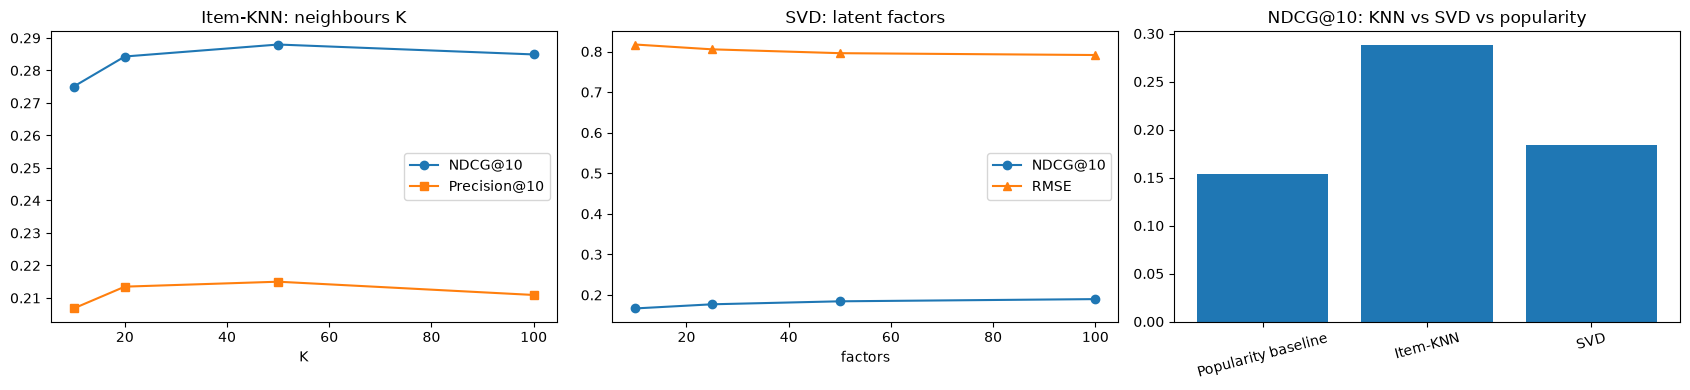

In [21]:
import matplotlib.pyplot as plt

pop_pu = ranking_metrics(pop_score_block)
res = pd.DataFrame(results)
knn_row = res[(res.model == "Item-KNN") & (res.setting == "K=50")].iloc[0]
svd_row = res[(res.model == "SVD") & (res.setting == "factors=50")].iloc[0]
pop_row = summarise(pop_pu)
results.append({"experiment": "knn_vs_svd", "model": "Popularity baseline", "setting": "-", **pop_row})
results.append({"experiment": "knn_vs_svd", "model": "Item-KNN", "setting": "K=50", **{c: knn_row[c] for c in res.columns if c not in ("experiment", "model", "setting")}})
results.append({"experiment": "knn_vs_svd", "model": "SVD", "setting": "factors=50", **{c: svd_row[c] for c in res.columns if c not in ("experiment", "model", "setting")}})

# Same-format table as the work plan
metrics = ["RMSE", "MAE", "Precision@10", "Recall@10", "NDCG@10", "train_time_s"]
comp = pd.DataFrame({"Item-KNN (K=50)": [knn_row[m] for m in metrics],
                     "SVD (50 factors)": [svd_row[m] for m in metrics],
                     "Popularity baseline": [np.nan, np.nan, pop_row["Precision@10"], pop_row["Recall@10"], pop_row["NDCG@10"], np.nan]},
                    index=["RMSE", "MAE", "Precision@10", "Recall@10", "NDCG@10", "Training time (s)"])
display(comp.round(4))

# Users with different rating histories (history size = number of TRAIN ratings)
hist_n = n_u[eval_users]
groups = {"light (<30 ratings)": hist_n < 30, "medium (30-100)": (hist_n >= 30) & (hist_n <= 100), "heavy (>100)": hist_n > 100}
grow = []
for g, mask in groups.items():
    for name, pu in [("Item-KNN", knn_per_user[50]), ("SVD", svd_per_user[50]), ("Popularity baseline", pop_pu)]:
        r_ = {"experiment": "history_group", "model": name, "setting": "K=50" if name == "Item-KNN" else ("factors=50" if name == "SVD" else "-"),
              "group": g, "n_users": int(mask.sum()),
              "Precision@10": float(pu["Precision@10"][mask].mean()), "Recall@10": float(pu["Recall@10"][mask].mean()),
              "NDCG@10": float(pu["NDCG@10"][mask].mean())}
        results.append(r_); grow.append(r_)
print("\nRanking quality (NDCG@10) by user history size:")
display(pd.DataFrame(grow).pivot(index="group", columns="model", values="NDCG@10").round(4).assign(
    users=[int(m.sum()) for m in groups.values()]).loc[list(groups)])

# Save
os.makedirs(os.path.join("..", "evaluation"), exist_ok=True)
out_path = os.path.join("..", "evaluation", "results_collaborative.csv")
pd.DataFrame(results).to_csv(out_path, index=False)
print("\nSaved:", out_path, "| rows:", len(results))

# Charts
fig, ax = plt.subplots(1, 3, figsize=(17, 4))
kn = res[res.experiment == "knn_neighbours"]; sv = res[res.experiment == "svd_factors"]
ax[0].plot([10, 20, 50, 100], kn["NDCG@10"], marker="o", label="NDCG@10"); ax[0].plot([10, 20, 50, 100], kn["Precision@10"], marker="s", label="Precision@10")
ax[0].set_title("Item-KNN: neighbours K"); ax[0].set_xlabel("K"); ax[0].legend()
ax[1].plot([10, 25, 50, 100], sv["NDCG@10"], marker="o", label="NDCG@10"); ax[1].plot([10, 25, 50, 100], sv["RMSE"], marker="^", label="RMSE")
ax[1].set_title("SVD: latent factors"); ax[1].set_xlabel("factors"); ax[1].legend()
cmp_ = pd.DataFrame(results); cmp_ = cmp_[cmp_.experiment == "knn_vs_svd"]
ax[2].bar(cmp_.model, cmp_["NDCG@10"]); ax[2].set_title("NDCG@10: KNN vs SVD vs popularity"); ax[2].tick_params(axis="x", rotation=15)
plt.tight_layout(); plt.show()

Correction: the "users" column in the history-size table above is mislabeled. The table below has the correct counts (7248 / 12668 / 9695). The CSV was always correct.

In [22]:
tbl = pd.DataFrame(grow).pivot(index="group", columns="model", values="NDCG@10").round(4)
tbl["users"] = [int(groups[g].sum()) for g in tbl.index]
display(tbl.loc[list(groups)])

model,Item-KNN,Popularity baseline,SVD,users
group,,,,
light (<30 ratings),0.1863,0.0954,0.1027,7248
medium (30-100),0.2363,0.1154,0.1355,12668
heavy (>100),0.4315,0.2479,0.3094,9695
